In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ==============================
# 工具函数
# ==============================
def clamp(v):
    return max(0, min(255, int(round(v))))

def rgb_to_yuv_bt601(r, g, b):
    """
    RGB -> YUV (BT.601, full range)
    """
    y =  0.299 * r + 0.587 * g + 0.114 * b
    u = -0.169 * r - 0.331 * g + 0.500 * b + 128
    v =  0.500 * r - 0.419 * g - 0.081 * b + 128
    return clamp(y), clamp(u), clamp(v)

# ==============================
# 生成单色 YUY2
# ==============================
def gen_yuy2_c_file(width, height, rgb_hex,
                    var_name="yuy2_frame",
                    out_file="yuy2_frame.c"):
    if width % 2 != 0:
        raise ValueError("width must be even for YUV422")
    if len(rgb_hex) != 6:
        raise ValueError("color format must be RRGGBB")

    r = int(rgb_hex[0:2], 16)
    g = int(rgb_hex[2:4], 16)
    b = int(rgb_hex[4:6], 16)
    Y, U, V = rgb_to_yuv_bt601(r, g, b)

    size = width * height * 2
    pixel_pairs = width * height // 2

    with open(out_file, "w", encoding="utf-8") as f:
        f.write("/*\n")
        f.write(f" * Auto-generated YUV422 (YUY2) frame\n")
        f.write(f" * Resolution : {width}x{height}\n")
        f.write(f" * Color      : RGB #{rgb_hex.upper()}\n")
        f.write(f" * Format     : Y0 U Y1 V\n")
        f.write(" */\n\n")
        f.write("#include <stdint.h>\n\n")
        f.write(f"const uint8_t {var_name}[{size}] = {{\n")

        line_cnt = 0
        for _ in range(pixel_pairs):
            for b_ in (Y, U, Y, V):
                if line_cnt % 16 == 0:
                    f.write("    ")
                f.write(f"0x{b_:02X}, ")
                line_cnt += 1
                if line_cnt % 16 == 0:
                    f.write("\n")
        if line_cnt % 16 != 0:
            f.write("\n")
        f.write("};\n")

    print(f"Generated: {os.path.abspath(out_file)}")
    return os.path.abspath(out_file)

# ==============================
# 生成 SMPTE 色条 YUY2
# ==============================
def gen_smpte_bars_yuy2_c_file(width, height,
                               var_name="yuy2_smpte_bars",
                               out_file="yuy2_smpte_bars.c"):
    if width % 2 != 0:
        raise ValueError("width must be even for YUV422")

    # SMPTE 75% color bars (RGB)
    bars_rgb = [
        (255, 255, 255),  # White
        (255, 255,   0),  # Yellow
        (  0, 255, 255),  # Cyan
        (  0, 255,   0),  # Green
        (255,   0, 255),  # Magenta
        (255,   0,   0),  # Red
        (  0,   0, 255),  # Blue
    ]
    bars_yuv = [rgb_to_yuv_bt601(r, g, b) for r, g, b in bars_rgb]
    bar_width = width // len(bars_rgb)

    size = width * height * 2

    with open(out_file, "w", encoding="utf-8") as f:
        f.write("/*\n")
        f.write(" * Auto-generated SMPTE color bars (75%)\n")
        f.write(f" * Resolution : {width}x{height}\n")
        f.write(" * Format     : YUV422 (YUY2)\n")
        f.write(" * Colors     : White Yellow Cyan Green Magenta Red Blue\n")
        f.write(" */\n\n")
        f.write("#include <stdint.h>\n\n")
        f.write(f"const uint8_t {var_name}[{size}] = {{\n")

        line_cnt = 0
        for y in range(height):
            x = 0
            while x < width:
                # 左右两个像素共享 U/V
                bar0 = min(x // bar_width, len(bars_yuv) - 1)
                bar1 = min((x+1) // bar_width, len(bars_yuv) - 1)
                Y0, U0, V0 = bars_yuv[bar0]
                Y1, U1, V1 = bars_yuv[bar1]
                # U/V 取平均值
                U = (U0 + U1) // 2
                V = (V0 + V1) // 2
                for b_ in (Y0, U, Y1, V):
                    if line_cnt % 16 == 0:
                        f.write("    ")
                    f.write(f"0x{b_:02X}, ")
                    line_cnt += 1
                    if line_cnt % 16 == 0:
                        f.write("\n")
                x += 2
        if line_cnt % 16 != 0:
            f.write("\n")
        f.write("};\n")

    print(f"Generated SMPTE bars: {os.path.abspath(out_file)}")
    return os.path.abspath(out_file)



outfile = gen_yuy2_c_file(160, 120, "FF0000", var_name="yuy2_red", out_file="yuy2_red.c")

# outfile = gen_smpte_bars_yuy2_c_file(160, 120, var_name="yuy2_smpte_bars", out_file="yuy2_smpte_bars.c")


Generated: d:\Data\Workspace\th160\yuy2_red.c


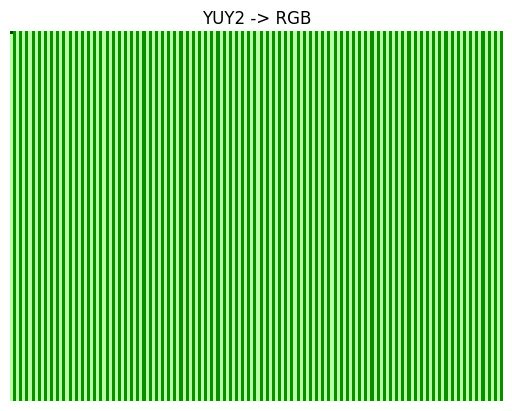

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================
# 配置
# ==============================
width = 160
height = 120
c_file = outfile

# ==============================
# 解析 C 数组
# ==============================
def load_yuy2_from_c(c_file):
    with open(c_file, "r", encoding="utf-8") as f:
        text = f.read()

    # 提取所有 0xXX 的十六进制数
    import re
    hex_bytes = re.findall(r'0x([0-9A-Fa-f]{2})', text)
    data = np.array([int(b, 16) for b in hex_bytes], dtype=np.uint8)
    return data

yuy2_data = load_yuy2_from_c(c_file)

# ==============================
# YUY2 -> RGB
# ==============================
def yuy2_to_rgb(yuy2, width, height):
    """
    yuy2: 1D numpy array
    return: HWC uint8 RGB image
    """
    rgb_img = np.zeros((height, width, 3), dtype=np.uint8)
    i = 0
    for y in range(height):
        for x in range(0, width, 2):
            Y0 = yuy2[i + 0]
            U  = yuy2[i + 1]
            Y1 = yuy2[i + 2]
            V  = yuy2[i + 3]
            i += 4

            # BT.601 full range YUV -> RGB
            for idx, Y in enumerate([Y0, Y1]):
                C = Y
                D = U - 128
                E = V - 128
                R = C + 1.402 * E
                G = C - 0.344136 * D - 0.714136 * E
                B = C + 1.772 * D
                rgb_img[y, x + idx, 0] = np.clip(R, 0, 255)
                rgb_img[y, x + idx, 1] = np.clip(G, 0, 255)
                rgb_img[y, x + idx, 2] = np.clip(B, 0, 255)
    return rgb_img

rgb_img = yuy2_to_rgb(yuy2_data, width, height)

# ==============================
# 显示图像
# ==============================
plt.imshow(rgb_img)
plt.title("YUY2 -> RGB")
plt.axis("off")
plt.show()
